# 01 – ScanNet++ scene inspection (Milestone 1)

Goal: load one ScanNet++ iPhone RGB-D sequence and verify, before any reconstruction, that we interpret
**depth units, image alignment, intrinsics and camera poses** correctly.

Verified conventions (see `src/volumetric_reasoning/datasets/scannetpp.py`):

| Item | Value |
|---|---|
| RGB | `rgb.mkv`, 1920×1440, 60 fps |
| Depth | `depth.bin`, 256×192, uint16 mm, LZ4-compressed per frame |
| Intrinsics | ARKit per-frame `intrinsic` (RGB resolution, pinhole), scaled ×(256/1920) for depth |
| Pose | `aligned_pose`: camera-to-world, OpenCV axes (x right, y down, z forward), laser-scan world frame, meters |

The laser-scan mesh is used **only for validation**, never as pipeline input.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import cv2
import open3d as o3d

from volumetric_reasoning.config import load_config, resolve_path
from volumetric_reasoning.datasets import ScanNetPPIphoneScene
from volumetric_reasoning.geometry.raycast import make_raycasting_scene, render_depth, depth_agreement

# ---- choose the scene here ---------------------------------------------
SCENE_ID = "1ada7a0617"   # None = use dataset.scene_id from configs/default.yaml / local.yaml
# --------------------------------------------------------------------------

cfg = load_config()
if SCENE_ID is not None:
    cfg["dataset"]["scene_id"] = SCENE_ID
scene = ScanNetPPIphoneScene(resolve_path(cfg["dataset"]["root"]), cfg["dataset"]["scene_id"])
print(f"scene {scene.scene_id}: {scene.num_frames} frames, "
      f"{(scene.timestamp(scene.num_frames - 1) - scene.timestamp(0)):.0f} s, RGB {scene.rgb_width}x{scene.rgb_height}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
scene 1ada7a0617: 5514 frames, 92 s, RGB 1920x1440


## Frame subset

In [2]:
indices = scene.select_frames(**cfg["frames"])
frames = scene.load_frames(indices)
print(f"{len(frames)} frames: {indices[:6]} ... {indices[-1]}")
f0 = frames[0]
print("K_rgb\n", f0.K_rgb.round(2))
print("K_depth\n", f0.K_depth.round(2))
print("cam_to_world\n", f0.cam_to_world.round(3))
print("rotation orthonormal:", np.allclose(f0.cam_to_world[:3, :3] @ f0.cam_to_world[:3, :3].T, np.eye(3), atol=1e-4),
      " det =", round(float(np.linalg.det(f0.cam_to_world[:3, :3])), 4))

92 frames: [0, 60, 120, 180, 240, 300] ... 5460
K_rgb
 [[1.42883e+03 0.00000e+00 9.53610e+02]
 [0.00000e+00 1.42883e+03 7.23960e+02]
 [0.00000e+00 0.00000e+00 1.00000e+00]]
K_depth
 [[190.51   0.   127.15]
 [  0.   190.51  96.53]
 [  0.     0.     1.  ]]
cam_to_world
 [[-0.18  -0.173  0.968  3.159]
 [-0.984  0.027 -0.178  3.628]
 [ 0.004 -0.985 -0.175  1.593]
 [ 0.     0.     0.     1.   ]]
rotation orthonormal: True  det = 1.0


## RGB and depth side by side

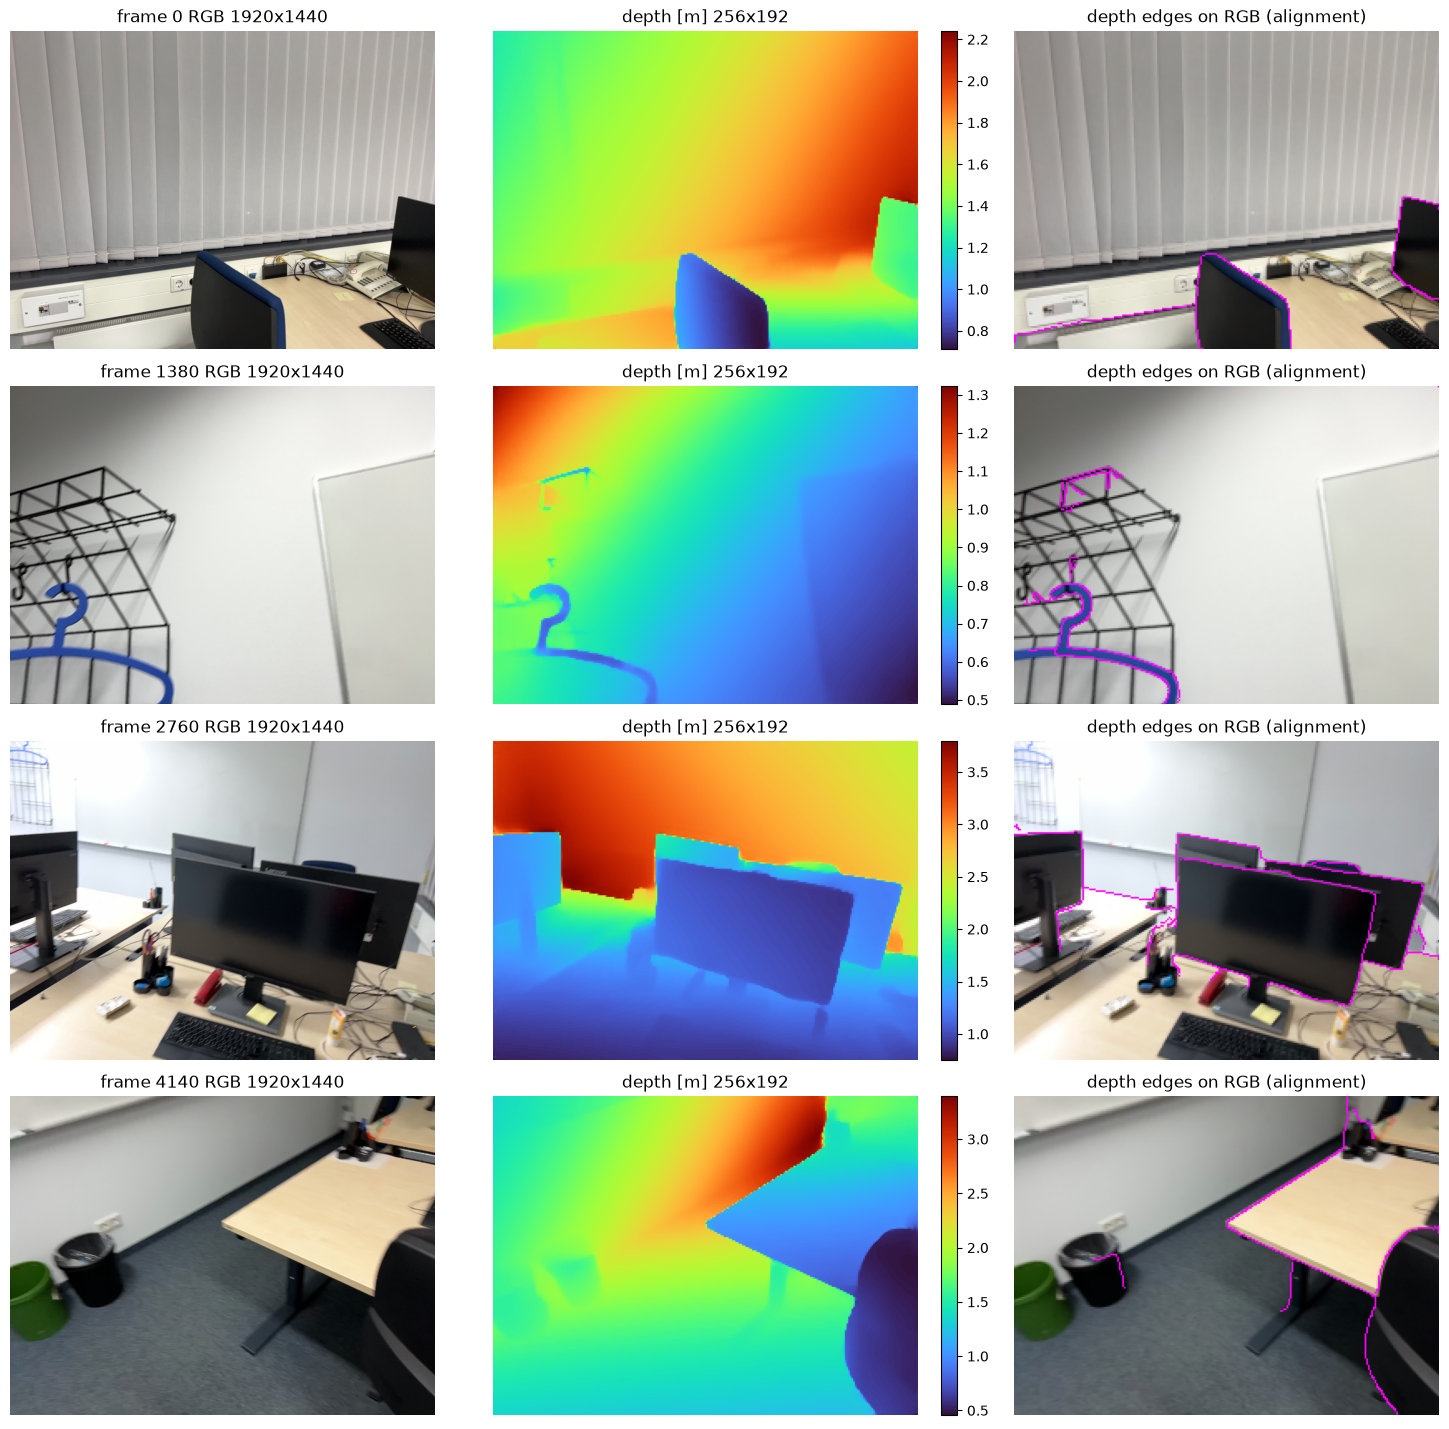

In [3]:
show = frames[:: max(1, len(frames) // 4)][:4]
fig, axes = plt.subplots(len(show), 3, figsize=(15, 3.6 * len(show)))
for row, f in zip(np.atleast_2d(axes), show):
    rgb_small = cv2.resize(f.rgb, f.depth.shape[::-1], interpolation=cv2.INTER_AREA)
    row[0].imshow(f.rgb); row[0].set_title(f"frame {f.index} RGB {f.rgb.shape[1]}x{f.rgb.shape[0]}")
    im = row[1].imshow(f.depth, cmap="turbo"); row[1].set_title("depth [m] 256x192")
    plt.colorbar(im, ax=row[1], fraction=0.035)
    # Alignment check: depth discontinuities (edges) drawn over the downsampled RGB.
    edges = cv2.Canny((f.depth / f.depth.max() * 255).astype(np.uint8), 20, 60) > 0
    overlay = rgb_small.copy(); overlay[edges] = [255, 0, 255]
    row[2].imshow(overlay); row[2].set_title("depth edges on RGB (alignment)")
    for a in row: a.axis("off")
plt.tight_layout()

## Depth statistics

ARKit depth contains no zeros (it is densified by ARKit), so invalid measurements are **not** marked.
Distant / reflective surfaces may therefore carry unreliable values; a max-depth cutoff will likely be needed for fusion.

invalid (0) fraction: 0.0000
percentiles [1, 50, 99, 100] (m): [ 0.43  1.39  3.97 12.98]


Text(0.5, 1.0, 'depth histogram')

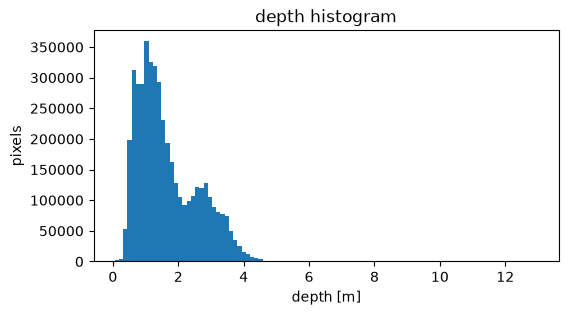

In [4]:
all_depth = np.concatenate([f.depth.ravel() for f in frames])
print(f"invalid (0) fraction: {(all_depth == 0).mean():.4f}")
print("percentiles [1, 50, 99, 100] (m):", np.percentile(all_depth, [1, 50, 99, 100]).round(2))
plt.figure(figsize=(6, 3)); plt.hist(all_depth, bins=100); plt.xlabel("depth [m]"); plt.ylabel("pixels"); plt.title("depth histogram")

## Camera trajectory over the reference mesh (top view)

mesh bounds min [0.05 0.01 0.04] max [5.48 4.46 3.47]
camera height z: 1.14 - 1.99 m


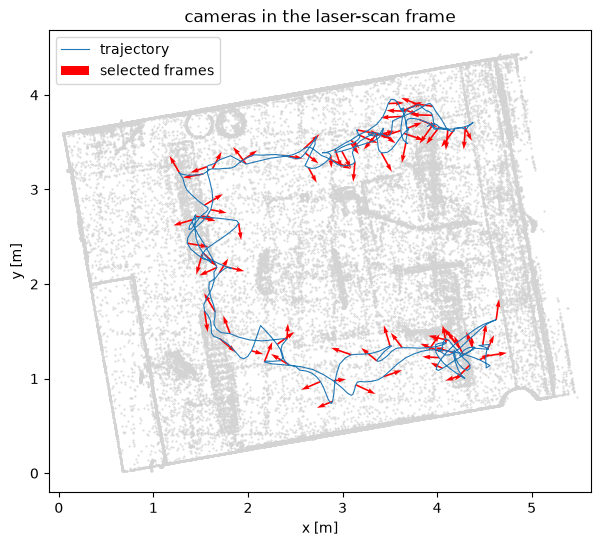

In [5]:
mesh = o3d.io.read_triangle_mesh(str(scene.mesh_path))
verts = np.asarray(mesh.vertices)
print("mesh bounds min", verts.min(0).round(2), "max", verts.max(0).round(2))

all_idx = scene.select_frames(stride=10)
centers = np.array([scene.cam_to_world(i)[:3, 3] for i in all_idx])
forward = np.array([scene.cam_to_world(i)[:3, 2] for i in indices])  # OpenCV: +z column = viewing direction
sel_centers = np.array([f.cam_to_world[:3, 3] for f in frames])

sub = verts[np.random.default_rng(0).choice(len(verts), 50_000, replace=False)]
plt.figure(figsize=(7, 6))
plt.scatter(sub[:, 0], sub[:, 1], s=0.2, c="lightgray")
plt.plot(centers[:, 0], centers[:, 1], "-", lw=0.8, label="trajectory")
plt.quiver(sel_centers[:, 0], sel_centers[:, 1], forward[:, 0], forward[:, 1], color="r", scale=25, width=0.003, label="selected frames")
plt.axis("equal"); plt.xlabel("x [m]"); plt.ylabel("y [m]"); plt.legend(); plt.title("cameras in the laser-scan frame")
print("camera height z: %.2f - %.2f m" % (centers[:, 2].min(), centers[:, 2].max()))

## Pose validation against the laser mesh

Render the reference mesh with each frame's pose and intrinsics and compare to the measured depth.
Correct conventions give errors of a few cm; a wrong convention (inverted pose, OpenGL axes, unscaled K) gives errors of ~1 m.

median |rendered - measured| over frames: median 2.2 cm, worst 15.4 cm (frame 1200)


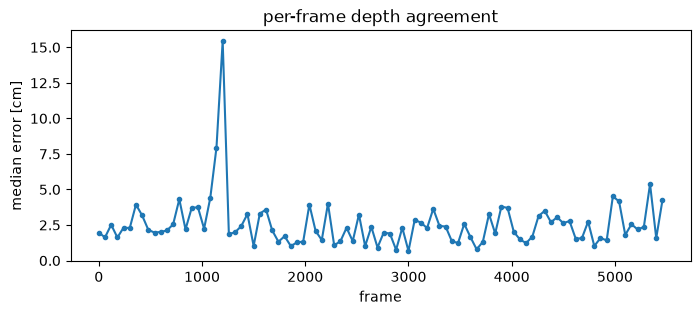

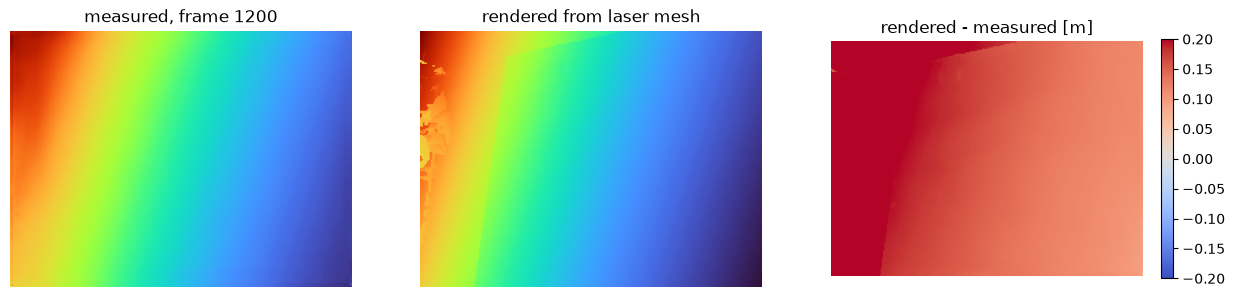

In [6]:
rc = make_raycasting_scene(mesh)
stats, rendered = [], {}
for f in frames:
    r = render_depth(rc, f.K_depth, f.cam_to_world, f.depth.shape[1], f.depth.shape[0])
    rendered[f.index] = r
    stats.append(depth_agreement(r, f.depth))
med = np.array([s["median_abs_err_m"] for s in stats])
print(f"median |rendered - measured| over frames: median {np.median(med)*100:.1f} cm, worst {med.max()*100:.1f} cm (frame {indices[int(med.argmax())]})")

plt.figure(figsize=(8, 3)); plt.plot(indices, med * 100, ".-"); plt.xlabel("frame"); plt.ylabel("median error [cm]"); plt.title("per-frame depth agreement")

f = frames[int(med.argmax())]
r = rendered[f.index]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].imshow(f.depth, cmap="turbo"); ax[0].set_title(f"measured, frame {f.index}")
ax[1].imshow(np.where(np.isfinite(r), r, np.nan), cmap="turbo"); ax[1].set_title("rendered from laser mesh")
im = ax[2].imshow(np.where(np.isfinite(r), r - f.depth, np.nan), cmap="coolwarm", vmin=-0.2, vmax=0.2); ax[2].set_title("rendered - measured [m]")
plt.colorbar(im, ax=ax[2], fraction=0.035)
for a in ax: a.axis("off")

## Optional: interactive 3D view

Opens a separate Open3D window with the reference mesh and camera frustums of the selected frames. Close the window to continue.

In [8]:
SHOW_3D = True
if SHOW_3D:
    geoms = [mesh]
    for f in frames:
        frustum = o3d.geometry.LineSet.create_camera_visualization(
            f.depth.shape[1], f.depth.shape[0], f.K_depth, np.linalg.inv(f.cam_to_world), scale=0.15)
        geoms.append(frustum)
    o3d.visualization.draw_geometries(geoms)

2026-11-02 17:03:28.077 Python[18546:316346] WARNING: Secure coding is automatically enabled for restorable state! However, not on all supported macOS versions of this application. Opt-in to secure coding explicitly by implementing NSApplicationDelegate.applicationSupportsSecureRestorableState:.


## Findings / next steps

- Fill in after running: alignment visually OK? depth range? any frames with large pose error?
- Next (Milestone 2): back-project depth into world-space point clouds and check multi-view alignment.